# 06 · PID control and tuning

Most industrial loops are closed with a PID controller: a proportional term for speed, an integral term for
zero offset, a derivative term for damping. This notebook takes the three terms apart on a third-order plant,
fits the first-order-plus-dead-time model that tuning rules want, applies Ziegler-Nichols, Cohen-Coon and
SIMC rules and compares them, measures the ultimate gain with a relay experiment instead of a model, and then
confronts the controller with reality: actuator saturation, integrator windup and the derivative kick.

**What you will learn**
- explain the role of each PID term and the need for a derivative filter
- fit a FOPDT model and apply Ziegler-Nichols, Cohen-Coon and SIMC rules
- run a relay autotuning experiment
- handle saturation, windup and the derivative kick in simulation

**Before you start:** notebooks 01 and 02  ·  **Time:** about 90 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, design as dg, response as rs, frequency as fr, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The three terms

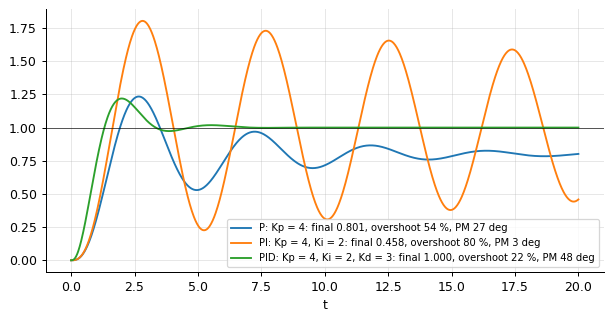

In [2]:
P = sy.tf([1.0], [1.0, 3.0, 3.0, 1.0])                 # 1/(s + 1)^3
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, (Kp, Ki, Kd) in (("P: Kp = 4", (4.0, 0.0, 0.0)), ("PI: Kp = 4, Ki = 2", (4.0, 2.0, 0.0)), ("PID: Kp = 4, Ki = 2, Kd = 3", (4.0, 2.0, 3.0))):
    C = dg.pid(Kp, Ki, Kd)
    cl = dg.closed_loop(P, C)
    t, y = rs.step(cl["T"], 20.0)
    m = fr.margins(cl["L"])
    ax.plot(t, y, label=f"{name}: final {y[-1]:.3f}, overshoot {rs.step_info(t, y, final=cl['T'].dcgain())['overshoot']:.0f} %, PM {m['phase_margin']:.0f} deg")
ax.axhline(1, color="k", lw=0.5); ax.legend(fontsize=8); ax.set_xlabel("t"); plt.show()

Proportional control alone leaves an offset (the final value 0.8 = K/(1 + K) for unit plant gain); the integral
term removes it but lowers the phase margin and raises the overshoot; the derivative term adds phase lead
near the crossover and recovers damping. The library's PID carries a filter on the derivative (time constant
K_d/(K_p N), N = 10) because an unfiltered derivative is improper and amplifies measurement noise without bound.

## A model for the tuning rules: FOPDT

first-order-plus-dead-time fit of 1/(s+1)^3: K = 1.000, tau = 2.110, L = 1.147


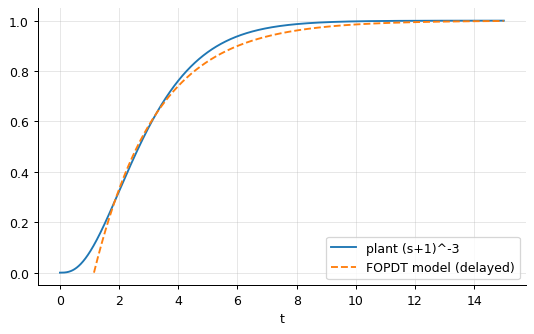

ultimate gain of the plant: Ku = 8.000 at w = 1.7321 (Pu = 3.628 s): the classical closed-loop ZN quantities


In [3]:
t, y = rs.step(P, 15.0, 3001)
fo = dg.fopdt_from_step(t, y)
print(f"first-order-plus-dead-time fit of 1/(s+1)^3: K = {fo['K']:.3f}, tau = {fo['tau']:.3f}, L = {fo['L']:.3f}")
Pf = sy.tf([fo["K"]], [fo["tau"], 1.0])
t_after = t[t >= fo["L"]]
_, yf = rs.step(Pf, t_after[-1] - t_after[0], len(t_after))
plt.plot(t, y, label="plant (s+1)^-3"); plt.plot(t_after, yf, "--", label="FOPDT model (delayed)"); plt.legend(); plt.xlabel("t"); plt.show()
ug = dg.ultimate_gain(P)
print(f"ultimate gain of the plant: Ku = {ug['Ku']:.3f} at w = {ug['w_u']:.4f} (Pu = {ug['Pu']:.3f} s): the classical closed-loop ZN quantities")

The two-point method reads the times to 28 % and 63 % of the final value and returns K, τ and L; the
third-order plant's S-shaped response is approximated by a first-order lag of 1.8 s delayed by 1.3 s. The
ultimate gain and period are the other classical inputs, exact here from the phase crossover (K_u = 8 at
ω = √3 for (s+1)⁻³).

## Four tuning rules, one plant

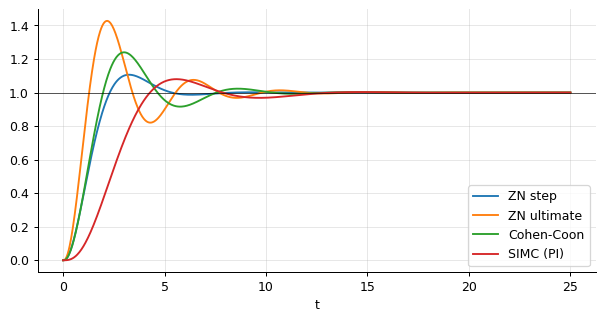

       rule   Kp   Ti   Td  overshoot %  settling (s)    GM  PM (deg)
    ZN step 2.21 2.29 0.57        10.63          4.88 18.62     57.44
ZN ultimate 4.80 1.81 0.45        42.72          9.20  9.05     29.43
 Cohen-Coon 2.70 2.33 0.38        23.98          9.10 14.76     43.00
  SIMC (PI) 0.92 2.11 0.00         7.98         11.20  4.90     60.39


In [4]:
rules = {"ZN step": dg.ziegler_nichols_step(fo["K"], fo["tau"], fo["L"])["PID"], "ZN ultimate": dg.ziegler_nichols_ultimate(ug["Ku"], ug["Pu"])["PID"],
         "Cohen-Coon": dg.cohen_coon(fo["K"], fo["tau"], fo["L"])["PID"], "SIMC (PI)": dg.imc_pid(fo["K"], fo["tau"], fo["L"])}
rows = []
fig, ax = plt.subplots(figsize=(8, 3.8))
for name, p_ in rules.items():
    C = dg.pid_standard(p_["Kp"], p_["Ti"], p_["Td"])
    cl = dg.closed_loop(P, C)
    t, y = rs.step(cl["T"], 25.0)
    info = rs.step_info(t, y, final=1.0)
    m = fr.margins(cl["L"])
    rows.append((name, p_["Kp"], p_["Ti"], p_["Td"], info["overshoot"], info["settling_time"], m["gain_margin"], m["phase_margin"]))
    ax.plot(t, y, label=name)
ax.axhline(1, color="k", lw=0.5); ax.legend(); ax.set_xlabel("t"); plt.show()
print(pd.DataFrame(rows, columns=["rule", "Kp", "Ti", "Td", "overshoot %", "settling (s)", "GM", "PM (deg)"]).to_string(index=False, float_format="%.2f"))

The Ziegler-Nichols ultimate-cycle rule was designed for quarter-amplitude decay - aggressive, with 40-60 %
overshoot and a phase margin around 30° - and Cohen-Coon is a milder relative; the ZN step rule happens to
come out gentle here because the FOPDT fit's long apparent delay makes it conservative (different rules read
the same plant differently). SIMC (Skogestad's simple IMC rule, λ = L) gives the calmest loop, with a 60°
margin at the cost of speed. There is no best rule, only a best trade-off for the
purpose: a tight temperature loop and a surge-prone level loop want different tunings, and the margins in the
table are the honest way to compare them.

## Tuning without a model: the relay experiment

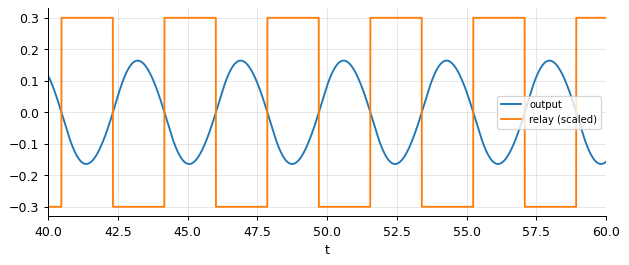

relay feedback: oscillation amplitude 0.1641, period 3.690 s -> Ku = 4d/(pi a) = 7.759 (exact 8.000), Pu (exact 3.628)


In [5]:
rl = dg.relay_experiment(P, amplitude=1.0, dt=0.005, T=80.0)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(rl["t"], rl["y"], label="output"); ax.plot(rl["t"], 0.3 * rl["u"], label="relay (scaled)"); ax.set_xlim(40, 60); ax.legend(fontsize=8); ax.set_xlabel("t"); plt.show()
print(f"relay feedback: oscillation amplitude {rl['amplitude']:.4f}, period {rl['Pu']:.3f} s -> Ku = 4d/(pi a) = {rl['Ku']:.3f} (exact {ug['Ku']:.3f}), Pu (exact {ug['Pu']:.3f})")

Replacing the controller by a relay makes the loop oscillate at the ultimate frequency with an amplitude from
which the ultimate gain follows by the describing-function approximation K_u ≈ 4d/(πa). The estimates land
within a few percent of the exact values, and this is how autotuning buttons on industrial controllers work:
a few oscillation cycles, then a ZN-type rule. No model, no step test that disturbs the process.

## Reality: saturation, windup and the derivative kick

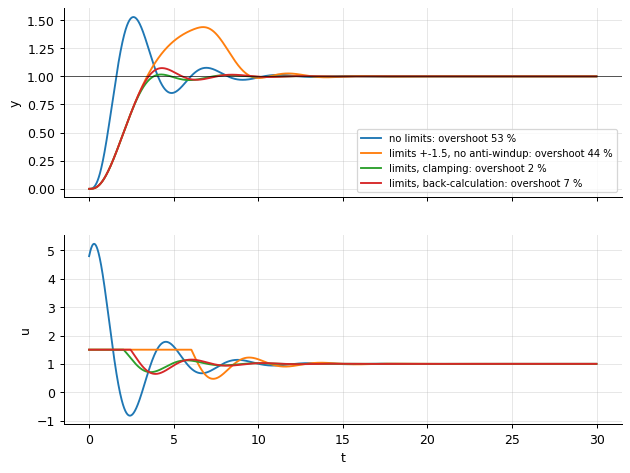

initial control move with the derivative on the error: 44.1; on the measurement: 4.9


In [6]:
zn = rules["ZN ultimate"]
Kp, Ki, Kd = zn["Kp"], zn["Kp"] / zn["Ti"], zn["Kp"] * zn["Td"]
runs = {"no limits": dg.simulate_pid(P, Kp, Ki, Kd, 1.0, T=30.0), "limits +-1.5, no anti-windup": dg.simulate_pid(P, Kp, Ki, Kd, 1.0, T=30.0, u_limits=(-1.5, 1.5), antiwindup=None),
        "limits, clamping": dg.simulate_pid(P, Kp, Ki, Kd, 1.0, T=30.0, u_limits=(-1.5, 1.5), antiwindup="clamping"), "limits, back-calculation": dg.simulate_pid(P, Kp, Ki, Kd, 1.0, T=30.0, u_limits=(-1.5, 1.5), antiwindup="back-calculation")}
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
for name, r in runs.items():
    axes[0].plot(r["t"], r["y"], label=f"{name}: overshoot {100 * (r['y'].max() - 1):.0f} %"); axes[1].plot(r["t"], r["u"])
axes[0].axhline(1, color="k", lw=0.5); axes[0].legend(fontsize=8); axes[0].set_ylabel("y"); axes[1].set_ylabel("u"); axes[1].set_xlabel("t"); plt.show()
kick = dg.simulate_pid(P, Kp, Ki, Kd, 1.0, T=2.0, derivative_on="error")
nokick = dg.simulate_pid(P, Kp, Ki, Kd, 1.0, T=2.0)
print(f"initial control move with the derivative on the error: {np.abs(kick['u'][:3]).max():.1f}; on the measurement: {np.abs(nokick['u'][:3]).max():.1f}")

With the actuator limited to ±1.5 the integrator keeps accumulating error while the output cannot follow -
*windup* - and the overshoot grows from 50 % to over 70 % with a long recovery. Clamping the integrator while
saturated helps; back-calculation (feeding the saturation excess back into the integrator) nearly restores the
unsaturated behaviour. The derivative kick is the other practical issue: differentiating the error turns a
setpoint step into an impulse in the control signal (an initial move of 100 against 5), which is why the
derivative is applied to the measurement in practice. These are not refinements; a PID without them does not
survive its first plant.

## Inside the algorithm: one step of the discrete PID with back-calculation

In [7]:
Kp_, Ki_, Kd_, dt_, Tt_ = 2.0, 1.0, 0.5, 0.01, 0.5
I_, y_prev, e = 0.0, 0.0, 1.0                      # error 1 at the first sample
v = Kp_ * e + I_ - Kd_ * (0.0 - y_prev) / dt_      # unsaturated control
u_ = float(np.clip(v, -1.5, 1.5))
I_ += dt_ * (Ki_ * e + (u_ - v) / Tt_)             # the saturation excess (u - v) is fed back into the integrator
print(f"v = {v:.2f}, saturated u = {u_:.2f}, integrator after back-calculation {I_:.4f} (it would be {dt_ * Ki_ * e:.4f} without)")

v = 2.00, saturated u = 1.50, integrator after back-calculation 0.0000 (it would be 0.0100 without)


## Exercises
1. Tune a PI controller for the thermal process `models.thermal_process()` (K = 2, tau = 50, L = 5) by ZN step, Cohen-Coon and SIMC with lambda = L and lambda = 3L; simulate with `design.simulate_pid(..., delay=5)` and compare overshoot, settling time and the control effort. Which would you install?
2. Measure the ultimate gain of 1/(s + 1)^3 with the relay experiment using a hysteresis of 0.05 and relay amplitudes 0.5 and 2. How do the estimates change, and why does hysteresis bias the period?
3. **Implement it yourself:** write a discrete PID simulation with clamping anti-windup and a setpoint weighting b (proportional term on b r - y instead of r - y); show that b = 0.5 reduces the setpoint overshoot without changing the disturbance response.